<a href="https://colab.research.google.com/github/SkyFlowTraveler/CIFAR-10-MLP-and-CNN/blob/main/PetProject_CIFAR_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
from keras.datasets import mnist

# Скачать MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Train:", x_train.shape, y_train.shape)
print("Test: ", x_test.shape, y_test.shape)
print("dtype:", x_train.dtype)
print("range:", x_train.min(), x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (60000, 28, 28) (60000,)
Test:  (10000, 28, 28) (10000,)
dtype: uint8
range: 0 255


#Data Exploration (EDA)

In [3]:
print("Train:", x_train.shape, y_train.shape)
print("Test: ", x_test.shape, y_test.shape)
print("dtype:", x_train.dtype)
print("range:", x_train.min(), x_train.max())

Train: (60000, 28, 28) (60000,)
Test:  (10000, 28, 28) (10000,)
dtype: uint8
range: 0 255


In [4]:
print("Number of train images:", len(x_train))
print("Image shape:", x_train.shape[1:])
print("Number of classes:", len(np.unique(y_train)))
print("Classes:", np.unique(y_train))
print("Pixel values:", x_train.min(), x_train.max())

Number of train images: 60000
Image shape: (28, 28)
Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]
Pixel values: 0 255


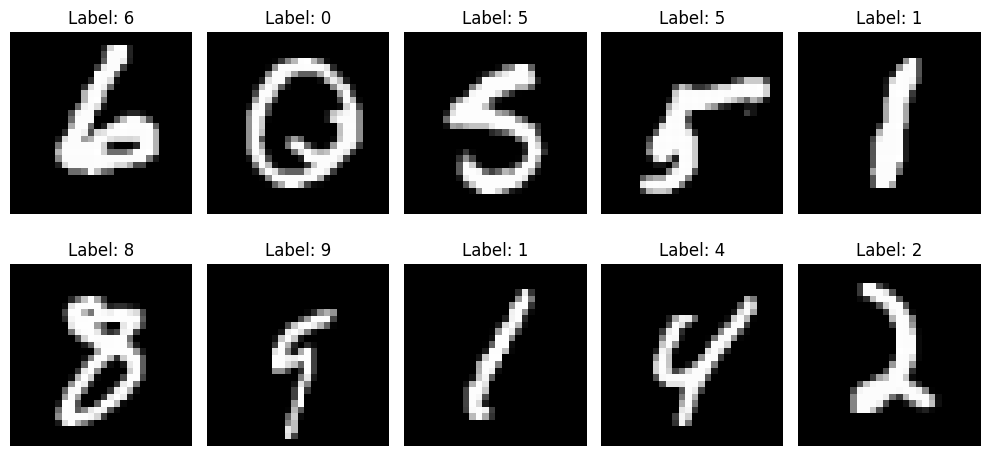

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for ax, idx in zip(axes.ravel(), np.random.choice(len(x_train), 10, replace=False)):
    ax.imshow(x_train[idx], cmap="gray")
    ax.set_title(f"Label: {y_train[idx]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


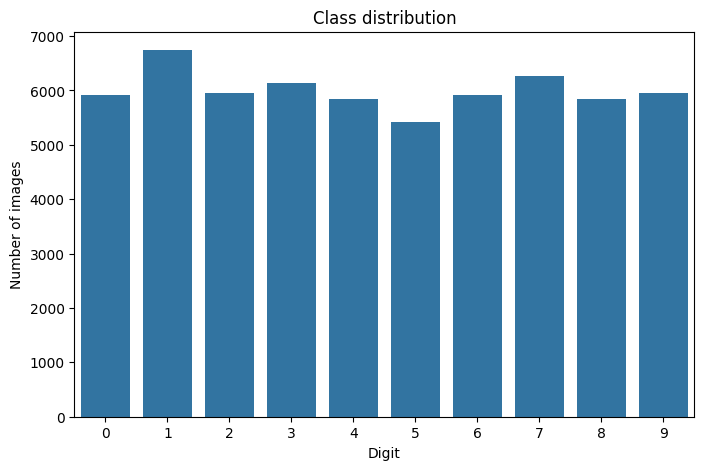

In [8]:
import pandas as pd
import seaborn as sns

counts = pd.Series(y_train).value_counts().sort_index()

print(counts)

plt.figure(figsize=(8, 5))

sns.countplot(x=y_train)

plt.title("Class distribution")
plt.xlabel("Digit")
plt.ylabel("Number of images")

plt.show()

Распределение классов train и test

      train    test
0  0.098717  0.0980
1  0.112367  0.1135
2  0.099300  0.1032
3  0.102183  0.1010
4  0.097367  0.0982
5  0.090350  0.0892
6  0.098633  0.0958
7  0.104417  0.1028
8  0.097517  0.0974
9  0.099150  0.1009


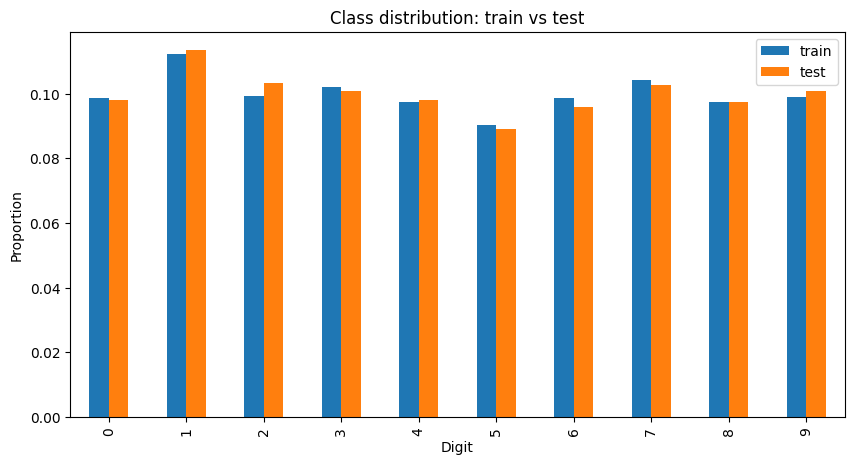

In [10]:
train_counts = pd.Series(y_train).value_counts(normalize=True).sort_index()
test_counts = pd.Series(y_test).value_counts(normalize=True).sort_index()

distribution = pd.DataFrame({
    "train": train_counts,
    "test": test_counts
})

distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Class distribution: train vs test")
plt.xlabel("Digit")
plt.ylabel("Proportion")

plt.show()

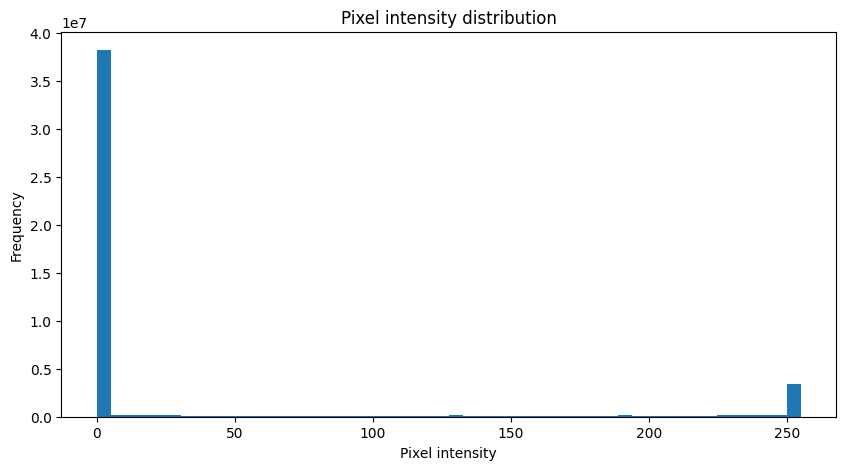

In [11]:
plt.figure(figsize=(10, 5))

plt.hist(x_train.flatten(), bins=50)

plt.title("Pixel intensity distribution")
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")

plt.show()

В каких областях изображения находится вся информация:

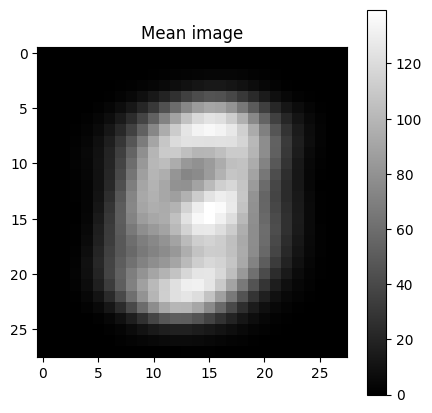

In [13]:
mean_image = x_train.mean(axis=0)

plt.figure(figsize=(5, 5))

plt.imshow(mean_image, cmap="gray")
plt.colorbar()

plt.title("Mean image")

plt.show()

Среднее изображение каждого класса:

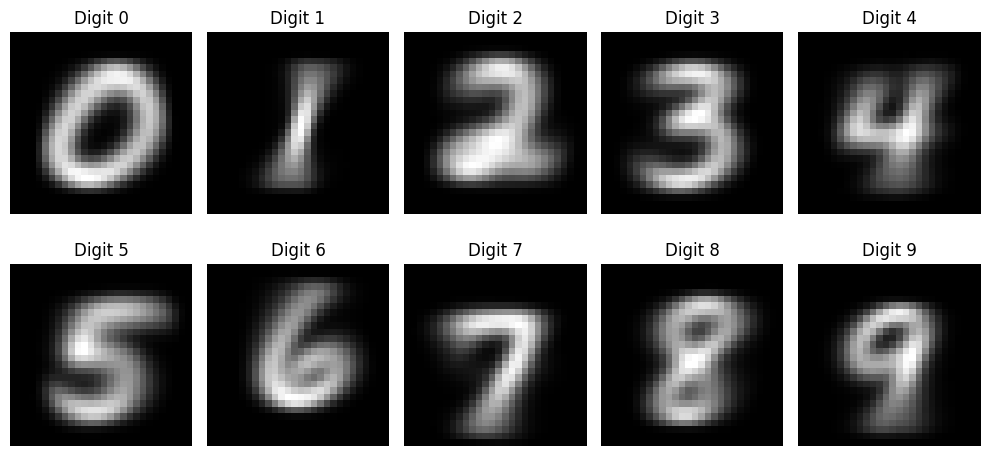

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for digit, ax in enumerate(axes.ravel()):
    mean_digit = x_train[y_train == digit].mean(axis=0)

    ax.imshow(mean_digit, cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()

В каких областях изображения наблюдается наибольшая вариативность:

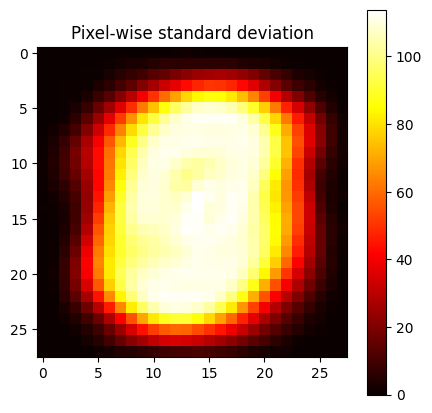

In [15]:
std_image = x_train.std(axis=0)

plt.figure(figsize=(5, 5))

plt.imshow(std_image, cmap="hot")
plt.colorbar()

plt.title("Pixel-wise standard deviation")

plt.show()

6.487244897959184
101.3813775510204


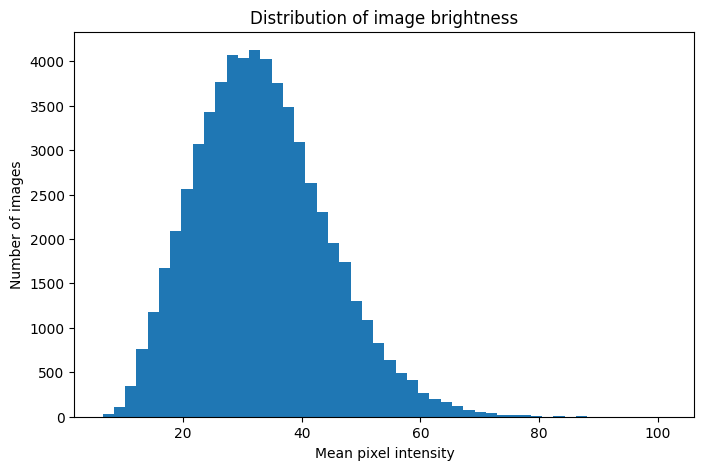

In [17]:
mean_brightness = x_train.mean(axis=(1, 2))

print(mean_brightness.min())
print(mean_brightness.max())

plt.figure(figsize=(8, 5))

plt.hist(mean_brightness, bins=50)

plt.title("Distribution of image brightness")
plt.xlabel("Mean pixel intensity")
plt.ylabel("Number of images")

plt.show()

Самые тёмные изображения(Это единицы, т.к. бОльшее количестве пикселей темное):

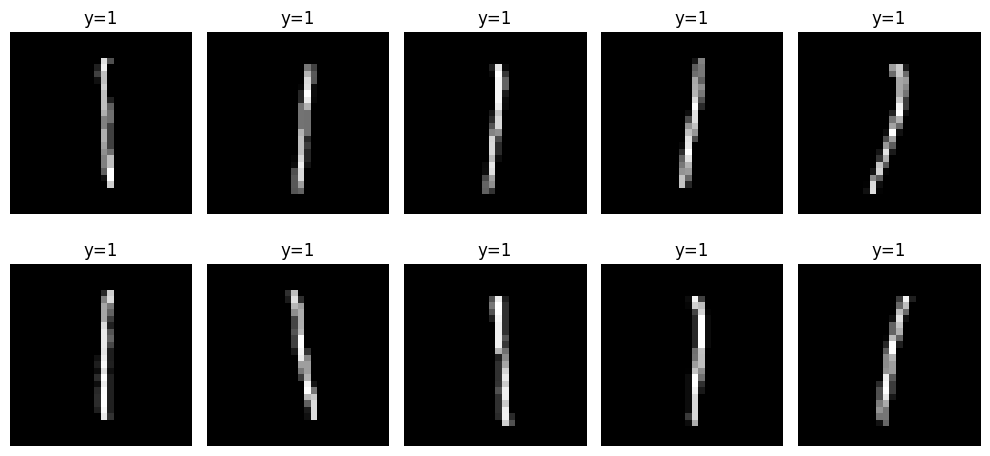

In [18]:
idx = np.argsort(mean_brightness)[:10]

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for ax, i in zip(axes.ravel(), idx):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"y={y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Наличие полных копий изображений:

In [20]:
X_flat = x_train.reshape(len(x_train), -1)

unique_images = np.unique(X_flat, axis=0)

print("Total duplicates:", len(X_flat)-len(unique_images))

Total duplicates: 0


# Подготовка данных

In [21]:
x_train.dtype

dtype('uint8')

Переводим во float32

In [22]:
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")

Нормализуем пиксели:

In [23]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [25]:
print(x_train.min(), x_train.max())

0.0 1.0


Создаём validation set

In [26]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

In [28]:
x_train = x_train[..., np.newaxis] #добавляем потому что канал 1 у grayscale
x_val = x_val[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# MLP Модель

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras import Sequential
from keras.layers import (
    Input,
    Flatten,
    Dense,
    Conv2D,
    MaxPooling2D,
    Dropout
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    precision_recall_curve,
    average_precision_score
)

In [36]:
mlp_model = keras.Sequential([
    keras.layers.Input(shape=(28, 28, 1)),
    keras.layers.Flatten(),

    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),

    keras.layers.Dense(10, activation="softmax")
])

mlp_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mlp_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
history_mlp = mlp_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9143 - loss: 0.2989 - val_accuracy: 0.9506 - val_loss: 0.1624
Epoch 2/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9657 - loss: 0.1162 - val_accuracy: 0.9613 - val_loss: 0.1190
Epoch 3/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9764 - loss: 0.0770 - val_accuracy: 0.9670 - val_loss: 0.1040
Epoch 4/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9833 - loss: 0.0549 - val_accuracy: 0.9700 - val_loss: 0.0908
Epoch 5/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9883 - loss: 0.0396 - val_accuracy: 0.9717 - val_loss: 0.0906
Epoch 6/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9907 - loss: 0.0298 - val_accuracy: 0.9689 - val_loss: 0.1125
Epoch 7/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9933 - loss: 0.0227 - val_accuracy: 0.9744 - val_loss: 0.0890
Epoch 8/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.9949 - loss: 0.0174 - val_accuracy

## CNN Model

In [38]:
cnn_model = keras.Sequential([
    keras.layers.Input(shape=(28, 28, 1)),

    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

# Тренировка и сравнение обеих моделей

In [44]:
history_mlp = mlp_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

history_cnn = cnn_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)


Epoch 1/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9992 - loss: 0.0028 - val_accuracy: 0.9765 - val_loss: 0.1292
Epoch 2/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9972 - loss: 0.0087 - val_accuracy: 0.9707 - val_loss: 0.1523
Epoch 3/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9968 - loss: 0.0099 - val_accuracy: 0.9731 - val_loss: 0.1367
Epoch 4/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9990 - loss: 0.0034 - val_accuracy: 0.9759 - val_loss: 0.1342
Epoch 5/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9985 - loss: 0.0045 - val_accuracy: 0.9761 - val_loss: 0.1243
Epoch 6/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9969 - loss: 0.0099 - val_accuracy: 0.9757 - val_loss: 0.1363
Epoch 7/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9982 - loss: 0.0056 - val_accuracy: 0.9750 - val_loss: 0.1364
Epoch 8/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9990 - loss: 0.0030 - val_accuracy:

In [46]:
y_prob_mlp = mlp_model.predict(x_test)
y_pred_mlp = np.argmax(y_prob_mlp, axis=1)

y_prob_cnn = cnn_model.predict(x_test)
y_pred_cnn = np.argmax(y_prob_cnn, axis=1)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


In [47]:
def evaluate_model(model_name, y_true, y_pred, y_prob):
    print(f"\n{'=' * 50}")
    print(model_name)
    print(f"{'=' * 50}")

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, average="macro"
    )
    recall = recall_score(
        y_true, y_pred, average="macro"
    )
    f1 = f1_score(
        y_true, y_pred, average="macro"
    )

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1       : {f1:.4f}")

    print("\nClassification report:")
    print(
        classification_report(
            y_true,
            y_pred,
            digits=4
        )
    )

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 7))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"{model_name} — Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


# Итог


MLP
Accuracy : 0.9815
Precision: 0.9815
Recall   : 0.9813
F1       : 0.9814

Classification report:
              precision    recall  f1-score   support

           0     0.9779    0.9929    0.9853       980
           1     0.9912    0.9921    0.9916      1135
           2     0.9787    0.9797    0.9792      1032
           3     0.9793    0.9832    0.9812      1010
           4     0.9796    0.9786    0.9791       982
           5     0.9886    0.9742    0.9814       892
           6     0.9863    0.9770    0.9816       958
           7     0.9834    0.9805    0.9820      1028
           8     0.9774    0.9774    0.9774       974
           9     0.9724    0.9772    0.9748      1009

    accuracy                         0.9815     10000
   macro avg     0.9815    0.9813    0.9814     10000
weighted avg     0.9815    0.9815    0.9815     10000



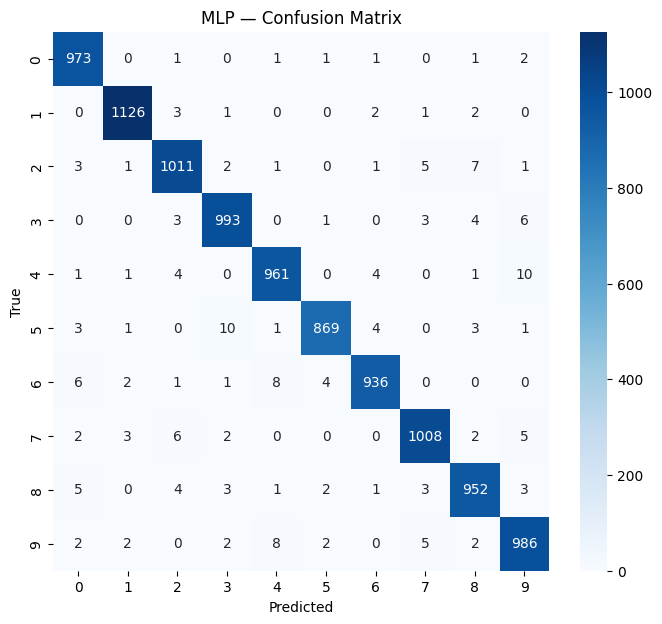


CNN
Accuracy : 0.9912
Precision: 0.9912
Recall   : 0.9911
F1       : 0.9911

Classification report:
              precision    recall  f1-score   support

           0     0.9909    0.9980    0.9944       980
           1     0.9982    0.9947    0.9965      1135
           2     0.9961    0.9884    0.9922      1032
           3     0.9892    0.9950    0.9921      1010
           4     0.9939    0.9929    0.9934       982
           5     0.9855    0.9877    0.9866       892
           6     0.9968    0.9885    0.9927       958
           7     0.9789    0.9951    0.9870      1028
           8     0.9969    0.9795    0.9881       974
           9     0.9852    0.9911    0.9881      1009

    accuracy                         0.9912     10000
   macro avg     0.9912    0.9911    0.9911     10000
weighted avg     0.9912    0.9912    0.9912     10000



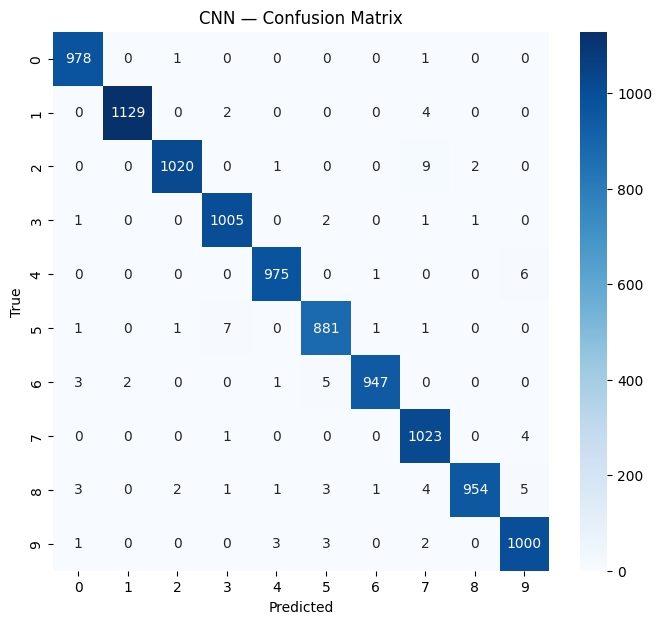

In [48]:
mlp_results = evaluate_model(
    "MLP",
    y_test,
    y_pred_mlp,
    y_prob_mlp
)

cnn_results = evaluate_model(
    "CNN",
    y_test,
    y_pred_cnn,
    y_prob_cnn
)


In [49]:
results = pd.DataFrame([
    mlp_results,
    cnn_results
])

results


,Model,Accuracy,Precision,Recall,F1
0,MLP,0.9815,0.981483,0.981278,0.981366
1,CNN,0.9912,0.991160,0.991083,0.991101


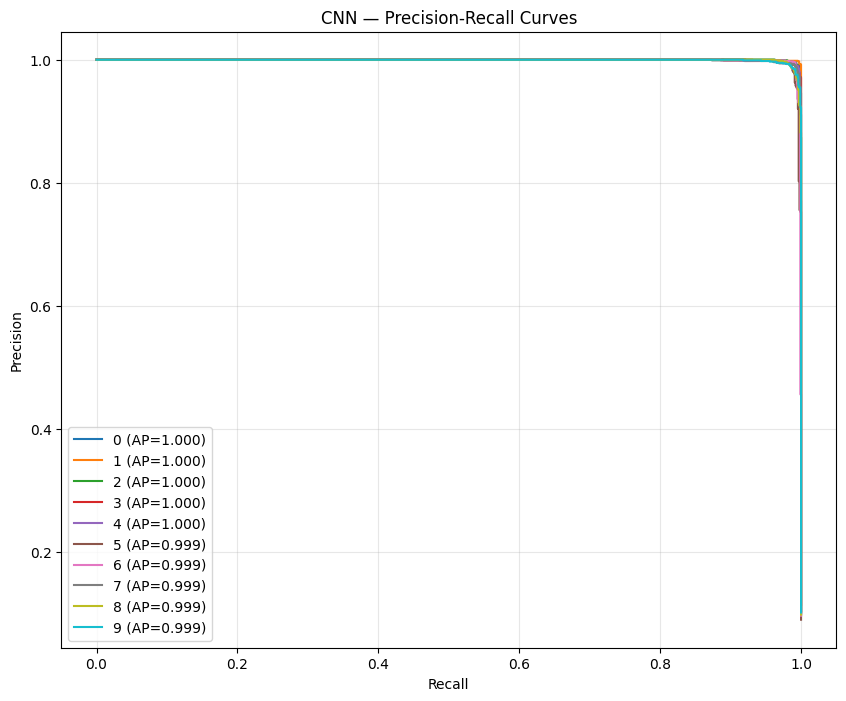

In [51]:
from sklearn.preprocessing import label_binarize

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(10)
)

plt.figure(figsize=(10, 8))

for digit in range(10):
    precision, recall, _ = precision_recall_curve(
        y_test_binary[:, digit],
        y_prob_cnn[:, digit]
    )

    ap = average_precision_score(
        y_test_binary[:, digit],
        y_prob_cnn[:, digit]
    )

    plt.plot(
        recall,
        precision,
        label=f"{digit} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("CNN — Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
